In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130


In [2]:
import torchvision
import torchvision.transforms as transforms

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)

100%|██████████| 170M/170M [13:26<00:00, 211kB/s]


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Image shape: torch.Size([3, 32, 32])
Label ID: 6
Class name: frog
Minimum pixel value: 0.0
Maximum pixel value: 1.0


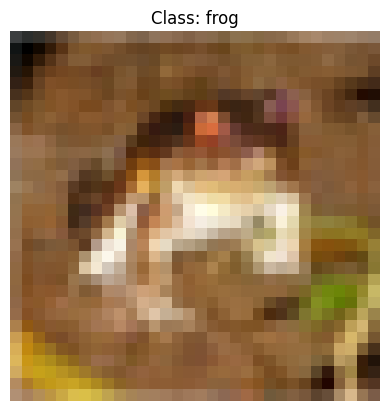

In [4]:
# Retrieve the first image and its label
image, label = train_dataset[0]

# Inspect the image
print("Image shape:", image.shape)
print("Label ID:", label)
print("Class name:", train_dataset.classes[label])
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

# Rearrange dimensions for Matplotlib
image_for_display = image.permute(1, 2, 0)

# Display the image
plt.imshow(image_for_display)
plt.title(f"Class: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

In [5]:

from torch.utils.data import DataLoader

# Create a DataLoader for the training dataset
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Retrieve one batch
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])


Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
First 10 labels: tensor([4, 0, 2, 2, 1, 1, 3, 5, 9, 0])


In [8]:
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [9]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class ThreeLayerCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model = ThreeLayerCNN()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(model)


ThreeLayerCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


After Conv1 + ReLU: torch.Size([64, 32, 32, 32])

After Pool1: torch.Size([64, 32, 16, 16])

After Conv2 + ReLU: torch.Size([64, 64, 16, 16])

After Pool2: torch.Size([64, 64, 8, 8])

After Conv3 + ReLU: torch.Size([64, 128, 8, 8])

After Pool3: torch.Size([64, 128, 4, 4])

After Flatten: torch.Size([64, 2048])
After FC1: torch.Size([64, 128])
After FC2: torch.Size([64, 10])

#Prepare training and validation data

In [13]:
from torch.utils.data import DataLoader, random_split

# Split the original training dataset
train_subset, val_subset = random_split(
    train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Create loaders
train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))


Training samples: 45000
Validation samples: 5000


#create a fresh model and optimizer.

In [14]:
import torch
import torch.nn as nn

# Start with a fresh model
model = ThreeLayerCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 5

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Evaluate on the validation set
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


Epoch 1/5 | Train Loss: 1.5699 | Train Acc: 42.80% | Val Loss: 1.3227 | Val Acc: 52.30%
Epoch 2/5 | Train Loss: 1.1698 | Train Acc: 58.34% | Val Loss: 1.0936 | Val Acc: 60.64%
Epoch 3/5 | Train Loss: 0.9762 | Train Acc: 65.80% | Val Loss: 0.9870 | Val Acc: 65.30%
Epoch 4/5 | Train Loss: 0.8488 | Train Acc: 70.51% | Val Loss: 0.8910 | Val Acc: 69.14%
Epoch 5/5 | Train Loss: 0.7576 | Train Acc: 73.65% | Val Loss: 0.8743 | Val Acc: 70.02%


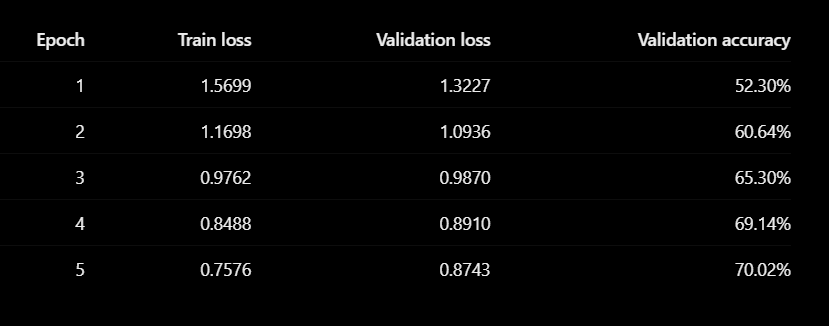

In [16]:

for epoch in range(5,15):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch {epoch + 1}/15 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


Epoch 6/15 | Train Loss: 0.6215 | Train Acc: 78.39% | Val Loss: 0.8281 | Val Acc: 71.64%
Epoch 7/15 | Train Loss: 0.5568 | Train Acc: 80.73% | Val Loss: 0.8047 | Val Acc: 73.34%
Epoch 8/15 | Train Loss: 0.4973 | Train Acc: 82.61% | Val Loss: 0.8166 | Val Acc: 72.92%
Epoch 9/15 | Train Loss: 0.4430 | Train Acc: 84.67% | Val Loss: 0.8433 | Val Acc: 73.12%
Epoch 10/15 | Train Loss: 0.3901 | Train Acc: 86.22% | Val Loss: 0.9419 | Val Acc: 71.80%
Epoch 11/15 | Train Loss: 0.3488 | Train Acc: 87.67% | Val Loss: 0.8947 | Val Acc: 73.92%
Epoch 12/15 | Train Loss: 0.2966 | Train Acc: 89.54% | Val Loss: 0.9703 | Val Acc: 72.48%
Epoch 13/15 | Train Loss: 0.2665 | Train Acc: 90.61% | Val Loss: 1.1144 | Val Acc: 71.64%
Epoch 14/15 | Train Loss: 0.2295 | Train Acc: 91.82% | Val Loss: 1.0574 | Val Acc: 73.18%
Epoch 15/15 | Train Loss: 0.1984 | Train Acc: 92.91% | Val Loss: 1.1206 | Val Acc: 72.86%


#Evaluate your CNN on the test dataset

In [17]:
# Create a DataLoader for the test dataset
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# Switch the model to evaluation mode
model.eval()

correct = 0
total = 0

# Disable gradient calculations during testing
with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Get predictions
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        # Count correct predictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

# Calculate test accuracy
test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 72.34%
Correct predictions: 7234/10000


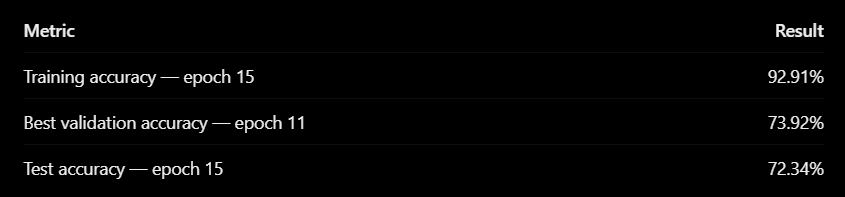

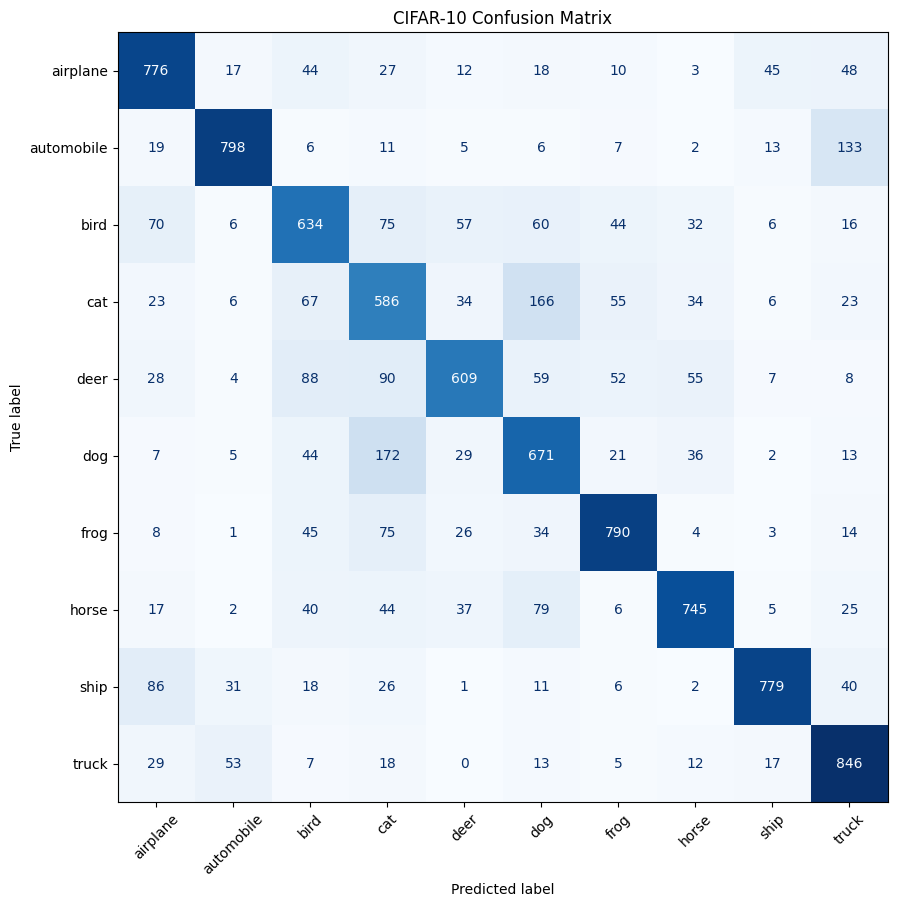

In [18]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

fig, ax = plt.subplots(figsize=(10, 10))
display.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("CIFAR-10 Confusion Matrix")
plt.show()


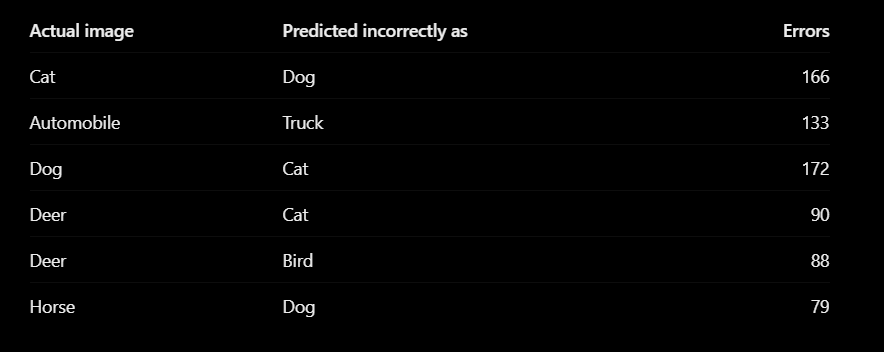

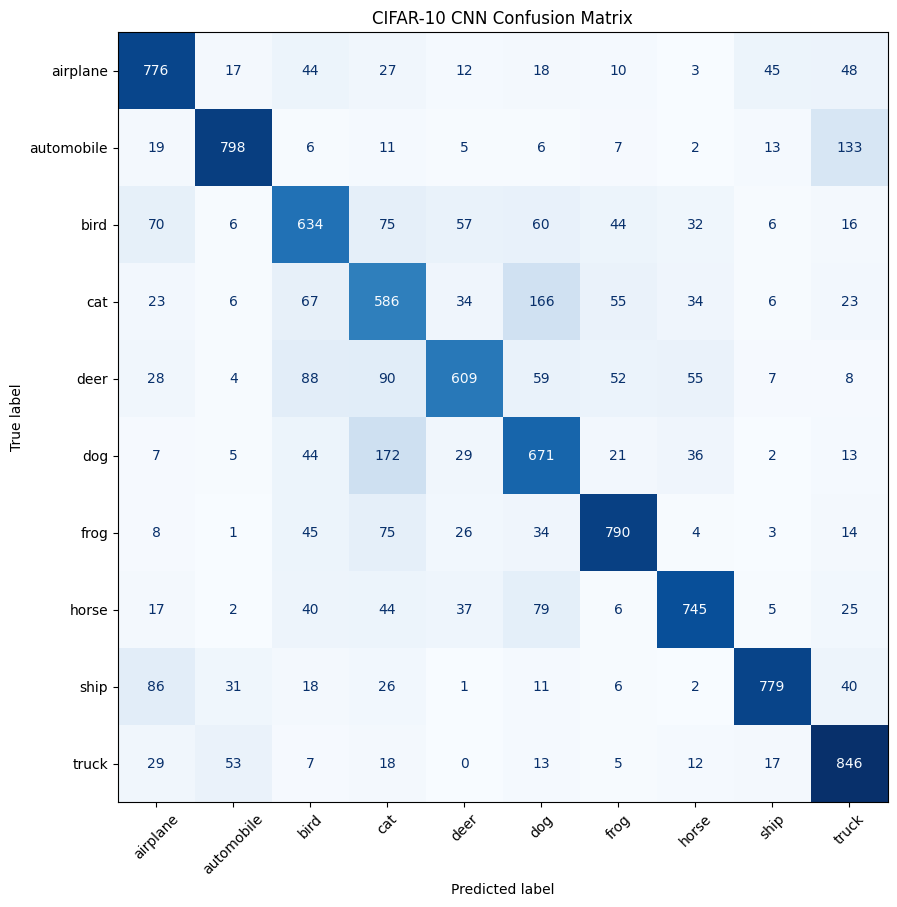

Confusion matrix saved!


In [20]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create the results folder
os.makedirs("results", exist_ok=True)

# Generate the confusion matrix using your existing predictions
cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

fig, ax = plt.subplots(figsize=(10, 10))
display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("CIFAR-10 CNN Confusion Matrix")
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved!")

#Add data augmentation

In [21]:

import torchvision
import torchvision.transforms as transforms

# Augmentation is applied only to training images
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

# Validation and test images remain unchanged
eval_transform = transforms.ToTensor()

# Create a training dataset with augmentation
augmented_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_transform
)

# Create an unchanged dataset for validation
eval_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=eval_transform
)

print("Augmentation transforms are ready!")


Augmentation transforms are ready!


#Create the DataLoaders

In [22]:

from torch.utils.data import DataLoader, Subset

# Reuse the exact split from our baseline experiment
train_indices = train_subset.indices
val_indices = val_subset.indices

# Apply augmentation only to the 45,000 training images
augmented_train_subset = Subset(
    augmented_train_dataset,
    train_indices
)

# Use unchanged images for validation
eval_val_subset = Subset(
    eval_train_dataset,
    val_indices
)

# Create DataLoaders
augmented_train_loader = DataLoader(
    augmented_train_subset,
    batch_size=64,
    shuffle=True
)

augmented_val_loader = DataLoader(
    eval_val_subset,
    batch_size=64,
    shuffle=False
)

print("Training images:", len(augmented_train_subset))
print("Validation images:", len(eval_val_subset))


Training images: 45000
Validation images: 5000


#Training a fresh CNN with data augmentation

In [23]:

# Create a fresh model
aug_model = ThreeLayerCNN().to(device)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
aug_optimizer = torch.optim.Adam(
    aug_model.parameters(),
    lr=0.001
)

# Train for 15 epochs
num_epochs = 15

for epoch in range(num_epochs):
    aug_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Training loop
    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        aug_optimizer.zero_grad()
        outputs = aug_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        aug_optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation loop
    aug_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in augmented_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )


Epoch 1/15 | Train Loss: 1.6979 | Train Acc: 37.50% | Val Loss: 1.4558 | Val Acc: 46.48%
Epoch 2/15 | Train Loss: 1.3713 | Train Acc: 50.36% | Val Loss: 1.1822 | Val Acc: 57.60%
Epoch 3/15 | Train Loss: 1.2065 | Train Acc: 56.84% | Val Loss: 1.0298 | Val Acc: 63.62%
Epoch 4/15 | Train Loss: 1.0856 | Train Acc: 61.04% | Val Loss: 0.9973 | Val Acc: 64.36%
Epoch 5/15 | Train Loss: 1.0080 | Train Acc: 64.32% | Val Loss: 0.8959 | Val Acc: 68.20%
Epoch 6/15 | Train Loss: 0.9401 | Train Acc: 66.65% | Val Loss: 0.8825 | Val Acc: 69.34%
Epoch 7/15 | Train Loss: 0.8839 | Train Acc: 68.75% | Val Loss: 0.8567 | Val Acc: 70.56%
Epoch 8/15 | Train Loss: 0.8443 | Train Acc: 70.23% | Val Loss: 0.8022 | Val Acc: 71.26%
Epoch 9/15 | Train Loss: 0.8121 | Train Acc: 71.42% | Val Loss: 0.7605 | Val Acc: 73.70%
Epoch 10/15 | Train Loss: 0.7834 | Train Acc: 72.66% | Val Loss: 0.7270 | Val Acc: 74.76%
Epoch 11/15 | Train Loss: 0.7514 | Train Acc: 73.75% | Val Loss: 0.7398 | Val Acc: 73.76%
Epoch 12/15 | Train

In [24]:

import os
import torch

os.makedirs("models", exist_ok=True)

torch.save(
    {
        "epoch": 15,
        "model_name": "ThreeLayerCNN",
        "model_state_dict": aug_model.state_dict(),
        "optimizer_state_dict": aug_optimizer.state_dict(),
        "validation_accuracy": 78.42,
    },
    "models/cifar10_cnn_augmented.pth"
)

print("Augmented model checkpoint saved!")


Augmented model checkpoint saved!


In [25]:

import torch

checkpoint = torch.load(
    "models/cifar10_cnn_augmented.pth",
    map_location=device,
    weights_only=True
)

print("Saved epoch:", checkpoint["epoch"])
print("Saved validation accuracy:", checkpoint["validation_accuracy"])
print("Saved model name:", checkpoint["model_name"])


Saved epoch: 15
Saved validation accuracy: 78.42
Saved model name: ThreeLayerCNN


#creating a new model with checkpoint and early stopping using augmented training data

In [26]:
import copy
import torch
import torch.nn as nn

# Start a new experiment
best_model = ThreeLayerCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    best_model.parameters(),
    lr=0.001
)

best_val_accuracy = 0.0
patience = 4
epochs_without_improvement = 0
num_epochs = 25

#Testing the new model with 25 epochs

In [27]:

import os

os.makedirs("models", exist_ok=True)

for epoch in range(num_epochs):
    best_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Training
    for images, labels in augmented_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = best_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation
    best_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in augmented_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = best_model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                (outputs.argmax(dim=1) == labels).sum().item()
            )
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    # Save whenever validation accuracy improves
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": best_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_accuracy": val_accuracy,
            },
            "models/best_cifar10_cnn.pth"
        )

        print("  Best checkpoint saved!")
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    # Early stopping
    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

print(f"Best validation accuracy: {best_val_accuracy:.2f}%")


  Best checkpoint saved!
Epoch 1/25 | Train Loss: 1.6843 | Train Acc: 37.66% | Val Loss: 1.3462 | Val Acc: 50.56%
  Best checkpoint saved!
Epoch 2/25 | Train Loss: 1.3268 | Train Acc: 51.83% | Val Loss: 1.1793 | Val Acc: 57.78%
  Best checkpoint saved!
Epoch 3/25 | Train Loss: 1.1582 | Train Acc: 58.68% | Val Loss: 1.0448 | Val Acc: 62.20%
  Best checkpoint saved!
Epoch 4/25 | Train Loss: 1.0431 | Train Acc: 62.97% | Val Loss: 0.9269 | Val Acc: 66.66%
  Best checkpoint saved!
Epoch 5/25 | Train Loss: 0.9719 | Train Acc: 65.71% | Val Loss: 0.8335 | Val Acc: 70.42%
  Best checkpoint saved!
Epoch 6/25 | Train Loss: 0.9078 | Train Acc: 68.10% | Val Loss: 0.8195 | Val Acc: 70.80%
Epoch 7/25 | Train Loss: 0.8586 | Train Acc: 69.91% | Val Loss: 0.8970 | Val Acc: 68.52%
  Best checkpoint saved!
Epoch 8/25 | Train Loss: 0.8245 | Train Acc: 71.12% | Val Loss: 0.7408 | Val Acc: 72.86%
  Best checkpoint saved!
Epoch 9/25 | Train Loss: 0.7903 | Train Acc: 72.42% | Val Loss: 0.7449 | Val Acc: 73.20%

#Evaluate the best model on the test set

In [29]:

best_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 79.73%
Correct predictions: 7973/10000


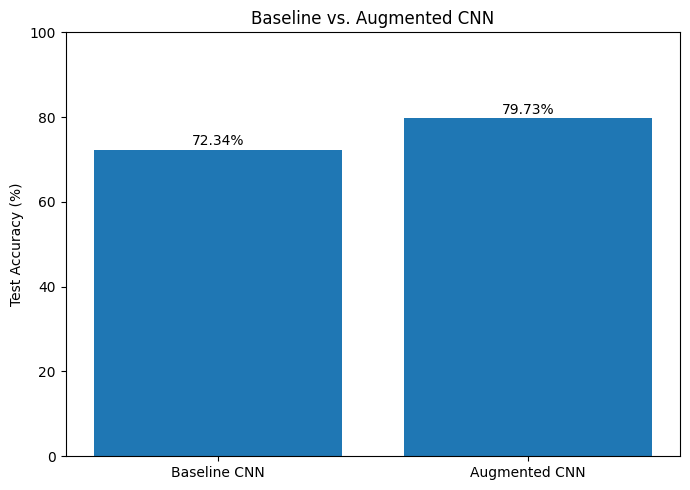

In [30]:

import matplotlib.pyplot as plt

models = ["Baseline CNN", "Augmented CNN"]
test_accuracies = [72.34, 79.73]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, test_accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("Baseline vs. Augmented CNN")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("results/model_comparison.png", dpi=300)
plt.show()


In [32]:

epochs = list(range(1, 26))

train_accuracy = [
    37.66, 51.83, 58.68, 62.97, 65.71,
    68.10, 69.91, 71.12, 72.42, 73.82,
    74.13, 75.22, 76.05, 76.66, 77.39,
    77.76, 77.71, 78.49, 78.93, 79.01,
    79.55, 79.78, 80.18, 80.59, 80.84
]

val_accuracy = [
    50.56, 57.78, 62.20, 66.66, 70.42,
    70.80, 68.52, 72.86, 73.20, 74.80,
    75.24, 76.18, 76.08, 76.30, 77.04,
    77.84, 77.10, 77.54, 78.14, 78.26,
    79.06, 78.70, 78.34, 79.30, 80.54
]

train_loss = [
    1.6843, 1.3268, 1.1582, 1.0431, 0.9719,
    0.9078, 0.8586, 0.8245, 0.7903, 0.7465,
    0.7359, 0.7113, 0.6873, 0.6702, 0.6535,
    0.6375, 0.6342, 0.6183, 0.6061, 0.5933,
    0.5862, 0.5752, 0.5643, 0.5557, 0.5454
]

val_loss = [
    1.3462, 1.1793, 1.0448, 0.9269, 0.8335,
    0.8195, 0.8970, 0.7408, 0.7449, 0.7353,
    0.7061, 0.6749, 0.6728, 0.6725, 0.6591,
    0.6185, 0.6444, 0.6514, 0.6233, 0.6318,
    0.6211, 0.6217, 0.6388, 0.6006, 0.5703
]

print("All 25 epochs of metrics are ready!")


All 25 epochs of metrics are ready!


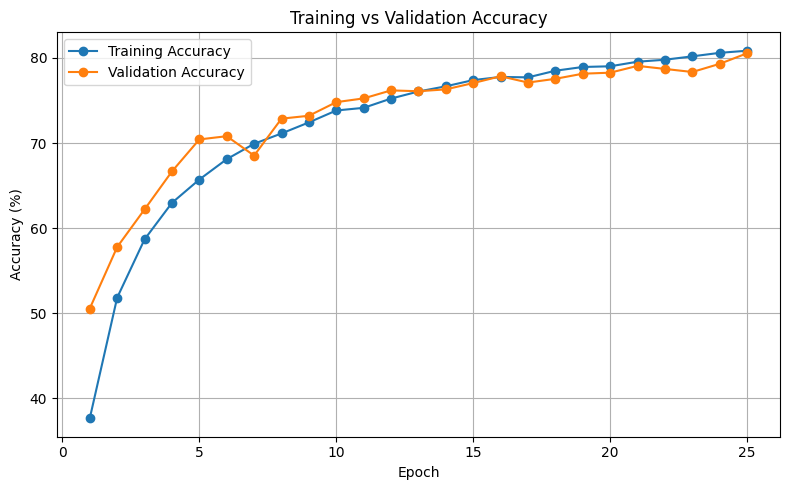

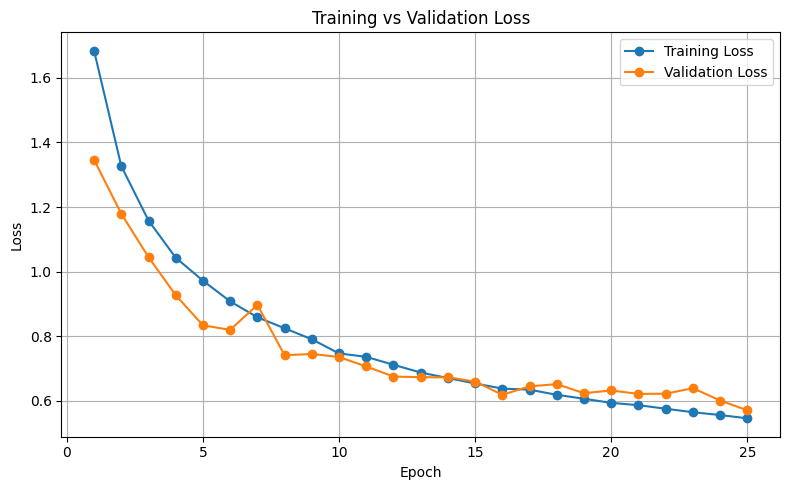

Both learning curves saved in results/


In [33]:

import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)

# Graph 1: Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/accuracy_curve.png", dpi=300)
plt.show()

# Graph 2: Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/loss_curve.png", dpi=300)
plt.show()

print("Both learning curves saved in results/")


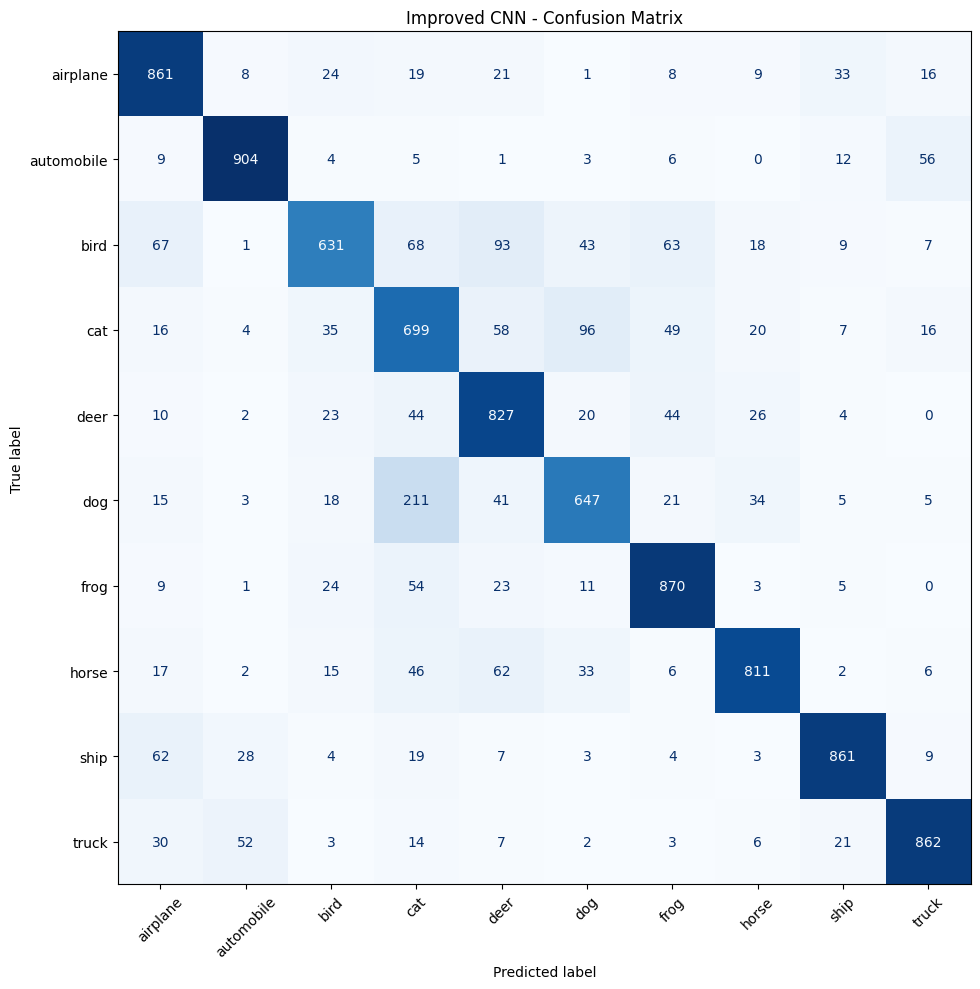

In [34]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

all_predictions_aug = []
all_labels_aug = []

best_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions_aug.extend(predictions.cpu().numpy())
        all_labels_aug.extend(labels.numpy())

cm_aug = confusion_matrix(
    all_labels_aug,
    all_predictions_aug
)

os.makedirs("results", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 10))

ConfusionMatrixDisplay(
    confusion_matrix=cm_aug,
    display_labels=train_dataset.classes
).plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Improved CNN - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "results/confusion_matrix_augmented.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
